# Evaluación Sumativa 3 — Cierre y comunicación del proyecto
## Dataset: *E-Commerce Shipping Data* (entregas atrasadas)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello
Equipo: José Ignacio Rodríguez, Yerko Gallardo Miranda y Sebastián Rojas Araya

Este cuaderno maestro cierra el proyecto. La Evaluación Sumativa 1 (S1) preguntó *¿qué características se asocian con el atraso y qué evidencia orienta una revisión operacional?* y la respondió con análisis exploratorio e inferencial. La Evaluación Sumativa 2 (S2) validó esas respuestas con remuestreo y simulación. Esta Evaluación Sumativa 3 (S3) aplica **regresión lineal múltiple** para imputar datos faltantes y **regresión logística** para clasificar el atraso. Cada decisión metodológica se fundamenta en un resultado de S1 o de S2.

| Sección | Contenido | Responsable |
|---|---|---|
| 0 | Configuración, datos, semilla, partición común y funciones compartidas | José |
| 1 | Punto de partida: hallazgos de S1 y S2 que guían cada decisión | José |
| 2 | Parte 1: datos faltantes, imputación por regresión y comparación de estrategias | Yerko |
| 3 | Parte 2: regresión logística (tres modelos, desempeño, selección, *bootstrap* y diagnóstico) | Sebastián; Yerko (3.4) |
| 4 | Parte 3: impacto de la estrategia de imputación en el modelo final | José |
| 5 | Síntesis y recomendaciones | José, con todo el equipo |

## 0. Configuración, datos, semilla y funciones compartidas

Los datos se leen desde S1 (`sumativa_1/data/raw/ecommerce_shipping.csv`) y se verifica su huella SHA-256 contra el registro de S1. Las cifras de referencia se leen desde las tablas publicadas de S1 (`sumativa_1/outputs/tablas/`), de S2 (`sumativa_2/outputs/`) y de la Formativa 2 (`formativa_2/outputs/tablas/`); no se recalculan.

**Semilla y flujos.** Toda la aleatoriedad usa la semilla de S2, registrada desde el *beacon* de aleatoriedad de la Universidad de Chile. De `SeedSequence(SEMILLA).spawn(10)` se derivan flujos independientes, en orden fijo:

- los hijos 0 a 6 son los de S2;
- el hijo 7 es el de la Formativa 2;
- el hijo **8** simula los faltantes de S3;
- el hijo **9** se reserva para el *bootstrap* de S3.

Así, reejecutar una sección no altera las demás.

**Partición común.** La partición 70/30 estratificada por el atraso se define **una sola vez** aquí, sobre los 10.999 envíos y con `random_state = SEMILLA`. Es la misma de la Formativa 2. Todas las estrategias de imputación y todos los modelos usan los mismos envíos de entrenamiento y prueba; en la estrategia de eliminación se usan los envíos que quedan de cada conjunto. Así las comparaciones de la Parte 3 no dependen del azar de la partición.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time

import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

# Raíz del repositorio: funciona al ejecutar desde el repositorio, sumativa_3/ o sus notebooks/
ubicacion = Path.cwd().resolve()
REPO = next((p for p in [ubicacion, *ubicacion.parents]
             if (p / 'sumativa_3/notebooks/sumativa_3_grupo1.ipynb').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Ejecute desde el repositorio, sumativa_3/ o sus notebooks/.')
RAIZ, S1, S2, F2 = REPO / 'sumativa_3', REPO / 'sumativa_1', REPO / 'sumativa_2', REPO / 'formativa_2'
TABLAS, FIGURAS = RAIZ / 'outputs/tablas', RAIZ / 'outputs/figuras'
for carpeta in (TABLAS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Datos: el CSV debe ser el registrado en S1
DATOS = S1 / 'data/raw/ecommerce_shipping.csv'
registro_fuente = json.loads((S1 / 'docs/registro_fuente.json').read_text(encoding='utf-8'))
HUELLA_DATOS = hashlib.sha256(DATOS.read_bytes()).hexdigest()
assert HUELLA_DATOS in {registro_fuente['file']['sha256'], registro_fuente['file']['sha256_lf_normalized']}, \
    'El CSV no coincide con el registrado en S1.'
raw = pd.read_csv(DATOS, encoding='utf-8-sig')
NOMBRES = {
    'ID': 'id_envio', 'Warehouse_block': 'bloque_bodega', 'Mode_of_Shipment': 'modalidad_envio',
    'Customer_care_calls': 'llamadas_atencion', 'Customer_rating': 'calificacion_cliente',
    'Cost_of_the_Product': 'costo_producto', 'Prior_purchases': 'compras_previas',
    'Product_importance': 'importancia_producto', 'Gender': 'genero',
    'Discount_offered': 'descuento_ofrecido', 'Weight_in_gms': 'peso_gramos',
}
TARGET = 'entrega_atrasada'
df = raw.rename(columns=NOMBRES)
df[TARGET] = raw['Reached.on.Time_Y.N']
df = df.drop(columns='Reached.on.Time_Y.N')
n, n_atr = len(df), int(df[TARGET].sum())
assert (n, n_atr, n - n_atr) == (10_999, 6_563, 4_436), 'Los conteos no coinciden con S1.'

# Tipos de variables (S1): numéricas continuas o discretas y categóricas nominales u ordinales
NUMERICAS = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas', 'llamadas_atencion',
             'calificacion_cliente']
CATEGORICAS = ['importancia_producto', 'bloque_bodega', 'modalidad_envio', 'genero']

# Semilla de S2 (beacon de la Universidad de Chile), verificada contra su pulso
registro_semilla = json.loads((S2 / 'docs/registro_semilla.json').read_text(encoding='utf-8'))
SEMILLA = registro_semilla['semilla']
assert SEMILLA == int(registro_semilla['pulso']['outputValue'], 16) % 2**32, 'La semilla no corresponde al pulso.'
FLUJOS = ['bootstrap_parametros', 'permutaciones', 'bootstrap_coeficientes', 'montecarlo_lotes',   # 0-3: S2
          'montecarlo_empirico', 'sensibilidad_escenarios', 'sensibilidad_montecarlo',             # 4-6: S2
          'formativa2_faltantes',                                                                    # 7: F2
          's3_faltantes', 's3_bootstrap']                                                            # 8-9: S3
SEMILLAS_FLUJO = dict(zip(FLUJOS, np.random.SeedSequence(SEMILLA).spawn(len(FLUJOS))))


def generador(flujo):
    # Generador nuevo del flujo indicado: reejecutar una sección reproduce sus mismos números
    return np.random.default_rng(SEMILLAS_FLUJO[flujo])


VERSIONES = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
                 statsmodels=statsmodels.__version__, sklearn=sklearn.__version__)
print(f'Datos: {DATOS.relative_to(REPO).as_posix()} (SHA-256 {HUELLA_DATOS[:12]}…)')
print(f'{n:,} envíos | atrasados: {n_atr:,} ({n_atr / n:.2%}) | puntuales: {n - n_atr:,}'.replace(',', '.'))
print(f'SEMILLA = {SEMILLA} | ' + ', '.join(f'{k} {v}' for k, v in VERSIONES.items()))

Datos: sumativa_1/data/raw/ecommerce_shipping.csv (SHA-256 dcdc3fd8f050…)
10.999 envíos | atrasados: 6.563 (59.67%) | puntuales: 4.436
SEMILLA = 1505514103 | python 3.14.4, numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, sklearn 1.9.1


In [2]:
from sklearn.model_selection import train_test_split

# Partición común 70/30, estratificada por el atraso: misma de la Formativa 2 (mismos parámetros)
IDX_TRAIN, IDX_TEST = train_test_split(df.index, test_size=0.30, stratify=df[TARGET], random_state=SEMILLA)
IDX_TRAIN, IDX_TEST = pd.Index(sorted(IDX_TRAIN)), pd.Index(sorted(IDX_TEST))
assert (len(IDX_TRAIN), len(IDX_TEST)) == (7_699, 3_300) and IDX_TRAIN.intersection(IDX_TEST).empty
assert abs(df.loc[IDX_TRAIN, TARGET].mean() - df.loc[IDX_TEST, TARGET].mean()) < 0.005


def particionar(datos):
    # Entrenamiento y prueba de un dataset: los envíos de la partición común que siguen presentes en él
    return datos.loc[datos.index.intersection(IDX_TRAIN)], datos.loc[datos.index.intersection(IDX_TEST)]


pd.DataFrame({'envios': [len(IDX_TRAIN), len(IDX_TEST)],
              'tasa_atraso': [df.loc[IDX_TRAIN, TARGET].mean(), df.loc[IDX_TEST, TARGET].mean()]},
             index=['entrenamiento', 'prueba']).round(4)

,envios,tasa_atraso
entrenamiento,7699,0.5967
prueba,3300,0.5967


In [3]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# Convención de figuras de S1, S2 y F2: negro = referencia; azul = modelo o S3; terracota = destacado; gris punteado = umbrales
AZUL, TERRA, GRIS, VERDE, GRID = '#1f5f8b', '#d1603d', '#555555', '#41866a', '#e1e4e8'
ANCHO = 6.3   # pulgadas: ancho de texto del informe
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42,
    'figure.constrained_layout.use': True, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 9, 'axes.labelsize': 8.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})
ETIQ = {'peso_gramos': 'Peso', 'descuento_ofrecido': 'Descuento', 'costo_producto': 'Costo',
        'compras_previas': 'Compras previas', 'llamadas_atencion': 'Llamadas', 'calificacion_cliente': 'Calificación',
        'importancia_producto': 'Importancia', 'bloque_bodega': 'Bodega', 'modalidad_envio': 'Modalidad',
        'genero': 'Género', TARGET: 'Atraso'}


def num(x, dec=0):
    # Formato es-CL: punto de miles, coma decimal y signo menos tipográfico
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.').replace('-', '−')


def guardar(nombre, fig):
    # Exporta en PDF (vectorial, para LaTeX) y PNG
    for ext in ('pdf', 'png'):
        fig.savefig(FIGURAS / f'{nombre}.{ext}')
    plt.show()

### Funciones compartidas

Las usan varias partes, para que la preparación, el ajuste y las métricas sean **idénticos** en los tres modelos de la Parte 2, en el *bootstrap* (3.4) y en la comparación de estrategias de la Parte 3. Así, las diferencias entre resultados se deben a los datos o al modelo, y no al código.

| Función | Uso |
|---|---|
| `disenar(datos, numericas, categoricas, entrenamiento)` | Matriz de diseño: estandariza las numéricas con la media y la DE **del entrenamiento** y codifica las categóricas en *dummies* (*one-hot* sin la primera categoría), con niveles fijos. |
| `ajustar_logit(X, y)` | Regresión logística por máxima verosimilitud (`statsmodels.Logit`) con intercepto. |
| `tabla_odds_ratios(modelo, escalas)` | Coeficientes, EE, *z*, *p*, IC 95 % de Wald y OR, por 1 DE y en unidades naturales. |
| `metricas_clasificacion(y, p, umbral)` | Matriz de confusión, accuracy, precision, recall, F1, especificidad y AUC. |
| `intervalos_bootstrap(replicas, estimacion, valores_jk)` | IC percentil y BCa: la misma función de S2, validada contra `scipy.stats.bootstrap`. |

In [4]:
from scipy.stats import norm
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score)

NIVELES = {c: sorted(df[c].astype(str).unique()) for c in CATEGORICAS}   # niveles fijos para todas las partes


def disenar(datos, numericas, categoricas, entrenamiento):
    # Matriz de diseño con parámetros del entrenamiento: numéricas estandarizadas y dummies sin la primera categoría
    media = entrenamiento[numericas].mean()
    de = entrenamiento[numericas].std(ddof=1)
    partes = [(datos[numericas] - media) / de]
    for c in categoricas:
        codif = pd.Categorical(datos[c].astype(str), categories=NIVELES[c])
        partes.append(pd.get_dummies(codif, prefix=c, drop_first=True, dtype=float).set_index(datos.index))
    return pd.concat(partes, axis=1)


def ajustar_logit(X, y):
    # Logit por máxima verosimilitud con intercepto; exige convergencia
    modelo = sm.Logit(y.astype(float), sm.add_constant(X, has_constant='add')).fit(disp=0, maxiter=200)
    if not modelo.mle_retvals['converged']:
        raise RuntimeError('El modelo logístico no convergió.')
    return modelo


def tabla_odds_ratios(modelo, escalas=None):
    # Coeficientes y OR con IC 95 % de Wald; escalas = {variable: (unidad, DE del entrenamiento, etiqueta)}
    ic = modelo.conf_int()
    tabla = pd.DataFrame({'coef': modelo.params, 'ee': modelo.bse, 'z': modelo.tvalues, 'p': modelo.pvalues,
                          'ic_inf': ic[0], 'ic_sup': ic[1]}).drop(index='const', errors='ignore')
    tabla['or'], tabla['or_inf'], tabla['or_sup'] = np.exp(tabla['coef']), np.exp(tabla['ic_inf']), np.exp(tabla['ic_sup'])
    for v, (unidad, de, etiqueta) in (escalas or {}).items():
        if v in tabla.index:   # OR por `unidad` en la escala original: exp(beta * unidad / DE)
            f = unidad / de
            tabla.loc[v, ['or_unidad', 'or_unidad_inf', 'or_unidad_sup']] = np.exp(tabla.loc[v, ['coef', 'ic_inf', 'ic_sup']].to_numpy(float) * f)
            tabla.loc[v, 'unidad'] = etiqueta
    return tabla


def metricas_clasificacion(y, p, umbral=0.5):
    # Métricas con umbral fijo y AUC (independiente del umbral)
    y, pred = np.asarray(y).astype(int), (np.asarray(p) >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'n': len(y), 'vp': vp, 'fp': fp, 'fn': fn, 'vn': vn, 'accuracy': accuracy_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred),
            'f1': f1_score(y, pred), 'especificidad': recall_score(y, pred, pos_label=0), 'auc': roc_auc_score(y, p)}


def intervalos_bootstrap(replicas, estimacion, valores_jk, tamanos=None, alfa=0.05):
    # Sesgo, EE, IC percentil y BCa (misma implementación de S2; aceleración por jackknife)
    rep = np.asarray(replicas, dtype=float)
    res = {'B': len(rep), 'sesgo': rep.mean() - estimacion, 'ee': rep.std(ddof=1),
           'ic_percentil_inf': np.quantile(rep, alfa / 2), 'ic_percentil_sup': np.quantile(rep, 1 - alfa / 2)}
    prop = (np.sum(rep < estimacion) + 0.5 * np.sum(rep == estimacion)) / len(rep)
    tamanos = [len(valores_jk)] if tamanos is None else list(tamanos)
    num_a = den_a = 0.0
    for v in np.split(np.asarray(valores_jk, dtype=float), np.cumsum(tamanos)[:-1]):
        u = (len(v) - 1) * (v.mean() - v)
        num_a += np.sum(u ** 3) / len(v) ** 3
        den_a += np.sum(u ** 2) / len(v) ** 2
    z0, a = norm.ppf(prop), num_a / (6 * den_a ** 1.5)
    z = norm.ppf([alfa / 2, 1 - alfa / 2])
    niveles = norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))
    res.update(z0=z0, aceleracion=a, ic_bca_inf=np.quantile(rep, niveles[0]), ic_bca_sup=np.quantile(rep, niveles[1]))
    return res


# Control de las funciones con los datos completos: reproduce el modelo de la Formativa 2 (mismos 4 predictores)
_tr, _te = particionar(df)
_cols = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas']
_m = ajustar_logit(disenar(_tr, _cols, [], _tr), _tr[TARGET])
_auc = metricas_clasificacion(_te[TARGET], _m.predict(sm.add_constant(disenar(_te, _cols, [], _tr))))['auc']
_auc_f2 = pd.read_csv(F2 / 'outputs/tablas/sensibilidad_modelo.csv', index_col=0).loc['datos originales (sin faltantes)', 'auc']
assert np.isclose(_auc, _auc_f2, atol=1e-10), 'Las funciones compartidas deben reproducir el AUC de la Formativa 2.'
print(f'Funciones compartidas verificadas: reproducen el AUC de la Formativa 2 con datos completos ({num(_auc, 4)}).')

Funciones compartidas verificadas: reproducen el AUC de la Formativa 2 con datos completos (0,7207).


## 1. Punto de partida: hallazgos de S1 y S2

Esta sección **no repite** análisis: lee los resultados publicados que fundamentan cada decisión de S3. La tabla resume el hilo conductor del proyecto.

| Hallazgo previo | Fuente | Decisión en S3 |
|---|---|---|
| La base no tiene valores faltantes (0 nulos en 10.999 envíos) | S1, `calidad_datos.csv` | Se simulan faltantes con un mecanismo conocido para ejercitar la imputación (Parte 1) |
| Matriz de Spearman entre las 5 variables numéricas | S1, `correlacion_spearman.csv` | Fuente de los predictores de cada regresión de imputación (Parte 1) |
| Estabilidad de cada correlación en 4 escenarios (completos, winsorización, exclusión IQR y descuento ≤ 10) | S2, `validacion_completa/tablas/sensibilidad_coeficientes.csv` | Se priorizan los predictores con correlación estable (Parte 1) |
| Extremos IQR válidos; winsorizar no cambia nada y excluir IQR cambia la población | S1 y S2 | Los outliers se conservan (Parte 2) |
| Correlaciones con el atraso, sus IC *bootstrap* y su estado validado | S1 y S2, `resultados_validados.csv` | Modelo M1 basado en S1 y S2 (Parte 2) |
| Modalidad sin asociación (T01); llamadas y calificación posiblemente posteriores a la entrega; envíos 1 a 3.135 todos atrasados | S1 y S2 | Exclusiones y candidatos de los modelos (Parte 2) |
| IC percentil y BCa validados, con B = 10.000 | S2 | Método de estabilidad del modelo final (3.4) |
| Logit de la Formativa 2: AUC 0,714; 0,52 con descuento ≤ 10 | Formativa 2 | Línea base y diagnóstico de linealidad (Parte 2) |

In [5]:
T1, T2V = S1 / 'outputs/tablas', S2 / 'outputs/validacion_completa/tablas'
calidad_s1 = pd.read_csv(T1 / 'calidad_datos.csv')
spearman_s1 = pd.read_csv(T1 / 'correlacion_spearman.csv', index_col=0)
cor_atraso_s1 = pd.read_csv(T1 / 'correlacion_dependiente_cuantitativas.csv').set_index('variable')
holm_s1 = pd.read_csv(T1 / 'contrastes_holm_7.csv').set_index('codigo')
validados_s2 = pd.read_csv(S2 / 'outputs/resultados_validados.csv').set_index('id')
sens_coef_s2 = pd.read_csv(T2V / 'sensibilidad_coeficientes.csv')
f2_modelo = pd.read_csv(F2 / 'outputs/tablas/sensibilidad_modelo.csv', index_col=0)

# 1) Faltantes en S1
faltantes_s1 = calidad_s1[calidad_s1['control'] == 'nulos_totales'][['control', 'variable', 'esperado', 'observado', 'detalle']]
assert int(faltantes_s1['observado'].iloc[0]) == 0 and df.isna().sum().sum() == 0

# 2) Estabilidad de cada correlación de Spearman entre variables numéricas (S1) en los escenarios de S2
rho = sens_coef_s2[sens_coef_s2['estimando'] == 'rho_spearman'].copy()
rho['excluye_cero'] = ~((rho['ic_inf'] <= 0) & (rho['ic_sup'] >= 0))
estabilidad = (rho.pivot_table(index='variable', columns='escenario', values='excluye_cero', aggfunc='first')
               .reindex(columns=['completos', 'winsor_01_99', 'exclusion_iqr', 'descuento_le10']))
estabilidad['estable_s2'] = estabilidad.all(axis=1)
pares = []
for par, fila in estabilidad.iterrows():
    a, b = par.split('|')
    if TARGET in (a, b):
        continue
    ic = rho[(rho['variable'] == par) & (rho['escenario'] == 'completos')].iloc[0]
    pares.append({'variable_1': a, 'variable_2': b, 'rho_s1': spearman_s1.loc[a, b], 'ic_s2_inf': ic['ic_inf'],
                  'ic_s2_sup': ic['ic_sup'], 'estable_s2': bool(fila['estable_s2']),
                  'escenarios_que_incluyen_cero': ', '.join(e for e in estabilidad.columns[:4] if not fila[e])})
pares_s1_s2 = pd.DataFrame(pares).sort_values('rho_s1', key=abs, ascending=False).reset_index(drop=True)
assert len(pares_s1_s2) == 10 and np.allclose(pares_s1_s2['rho_s1'], [rho.query("escenario == 'completos'").set_index('variable')
                                                                      .loc[f"{r.variable_1}|{r.variable_2}", 'estimacion_s1'] for r in pares_s1_s2.itertuples()])

# 3) Correlaciones con el atraso (S1) y su estado validado en S2
ID_COR = {'descuento_ofrecido': 'COR-1', 'peso_gramos': 'COR-2', 'costo_producto': 'COR-4', 'compras_previas': 'COR-5'}
atraso = pd.DataFrame({'r_punto_biserial_s1': cor_atraso_s1['r_punto_biserial'], 'rho_s1': cor_atraso_s1['rho_spearman'],
                       'estado_s2': [validados_s2.loc[ID_COR[v], 'estado'] if v in ID_COR else 'no evaluada en S2'
                                     for v in cor_atraso_s1.index]})

for nombre, tabla in [('punto_partida_pares_spearman', pares_s1_s2), ('punto_partida_correlaciones_atraso', atraso)]:
    tabla.to_csv(TABLAS / f'{nombre}.csv', index=nombre != 'punto_partida_pares_spearman')
print('Faltantes registrados en S1:')
display(faltantes_s1)
print('Correlaciones de Spearman entre variables numéricas (S1) y su estabilidad en los escenarios de S2:')
display(pares_s1_s2.round(3))
print('Correlaciones con el atraso (S1) y estado validado (S2):')
display(atraso.round(3))
print('Contrastes de S1 (valor p ajustado por Holm):')
display(holm_s1[['prueba', 'p_holm', 'decision_holm']])
print('Formativa 2 (modelo logístico de 4 predictores), AUC en prueba:')
display(f2_modelo[['n_prueba', 'auc', 'accuracy']].round(4))

Faltantes registrados en S1:


,control,variable,esperado,observado,detalle
1,nulos_totales,todas,0,0,Sin imputación ni faltantes artificiales


Correlaciones de Spearman entre variables numéricas (S1) y su estabilidad en los escenarios de S2:


,variable_1,variable_2,rho_s1,ic_s2_inf,ic_s2_sup,estable_s2,escenarios_que_incluyen_cero
0,descuento_ofrecido,peso_gramos,-0.316,-0.333,-0.298,False,descuento_le10
1,costo_producto,llamadas_atencion,0.294,0.275,0.312,True,
2,compras_previas,llamadas_atencion,0.273,0.256,0.290,True,
3,compras_previas,peso_gramos,-0.235,-0.253,-0.216,True,
4,llamadas_atencion,peso_gramos,-0.233,-0.252,-0.214,True,
5,compras_previas,costo_producto,0.194,0.176,0.212,True,
6,costo_producto,peso_gramos,-0.132,-0.152,-0.112,True,
7,costo_producto,descuento_ofrecido,-0.116,-0.134,-0.098,False,"exclusion_iqr, descuento_le10"
8,descuento_ofrecido,llamadas_atencion,-0.104,-0.123,-0.085,False,descuento_le10
9,compras_previas,descuento_ofrecido,-0.094,-0.112,-0.075,False,"exclusion_iqr, descuento_le10"


Correlaciones con el atraso (S1) y estado validado (S2):


,r_punto_biserial_s1,rho_s1,estado_s2
variable,,,
compras_previas,-0.056,-0.075,sensible
llamadas_atencion,-0.067,-0.064,no evaluada en S2
costo_producto,-0.074,-0.072,sensible
peso_gramos,-0.269,-0.266,"respaldado, magnitud sensible"
descuento_ofrecido,0.397,0.335,sensible


Contrastes de S1 (valor p ajustado por Holm):


,prueba,p_holm,decision_holm
codigo,,,
T01,Chi-cuadrado: modalidad y atraso,6.895488e-01,no se rechaza H0
T02,Welch: peso medio atrasadas vs puntuales,9.654651e-180,se rechaza H0
T03,Welch: descuento medio atrasadas vs puntuales,0.000000e+00,se rechaza H0
E1,Mann-Whitney U: peso atrasadas vs puntuales,1.359519e-170,se rechaza H0
E2,z dos proporciones: atraso importancia alta vs...,9.795259e-04,se rechaza H0
E3,z dos proporciones: atraso descuento > 10 vs <...,0.000000e+00,se rechaza H0
E4,Welch: costo medio atrasadas vs puntuales,3.107184e-14,se rechaza H0


Formativa 2 (modelo logístico de 4 predictores), AUC en prueba:


,n_prueba,auc,accuracy
principal (imputación por mediana),3300.0,0.7139,0.6282
"principal, prueba con descuento ≤ 10",2493.0,0.5205,0.5082
sin descuento,3300.0,0.6660,0.6167
casos completos (dropna),2651.0,0.7140,0.6273
datos originales (sin faltantes),3300.0,0.7207,0.6352


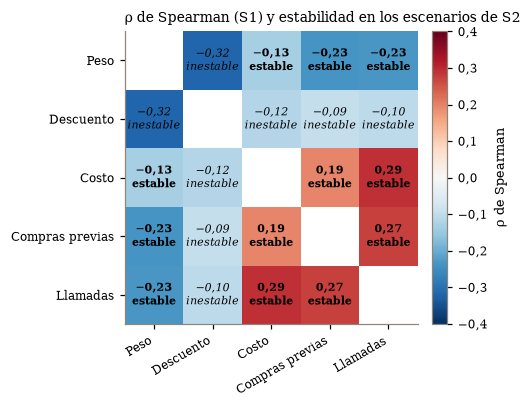

In [6]:
orden = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas', 'llamadas_atencion']
matriz = spearman_s1.loc[orden, orden]
estable = {frozenset((r.variable_1, r.variable_2)): r.estable_s2 for r in pares_s1_s2.itertuples()}
fig, ax = plt.subplots(figsize=(4.6, 3.8))
valores = matriz.to_numpy().copy()
np.fill_diagonal(valores, np.nan)   # la diagonal (rho = 1) no aporta información
im = ax.imshow(valores, cmap='RdBu_r', vmin=-0.4, vmax=0.4)
for i, a in enumerate(orden):
    for j, b in enumerate(orden):
        if i == j:
            continue
        ok = estable[frozenset((a, b))]
        ax.text(j, i, f"{num(matriz.loc[a, b], 2)}\n{'estable' if ok else 'inestable'}", ha='center', va='center',
                fontsize=7, color='black', fontweight='bold' if ok else 'normal', fontstyle='normal' if ok else 'italic')
ax.set_xticks(range(len(orden)), [ETIQ[v] for v in orden], rotation=30, ha='right')
ax.set_yticks(range(len(orden)), [ETIQ[v] for v in orden])
ax.grid(False)
ax.set_title('ρ de Spearman (S1) y estabilidad en los escenarios de S2')
fig.colorbar(im, ax=ax, shrink=0.8, label='ρ de Spearman', format=FuncFormatter(lambda v, _: num(v, 1)))
guardar('fig_0_matriz_estabilidad', fig)

#### Qué se lleva cada parte

- **Parte 1 (faltantes):**
  - S1 no registró faltantes, así que el análisis de faltantes parte de "0 % en todas las variables, sin patrón".
  - La matriz de Spearman y su estabilidad son la base para elegir los predictores de cada regresión de imputación. Las correlaciones **estables** forman el bloque peso–costo–compras previas–llamadas. Las del **descuento** con las demás variables numéricas son inestables: se anulan con descuento ≤ 10.
- **Parte 2 (logística):**
  - el peso es el único predictor con asociación robusta en todos los escenarios de S2;
  - el descuento es fuerte, pero depende del segmento > 10;
  - costo y compras previas son débiles y sensibles;
  - la modalidad no se asocia con el atraso (T01);
  - la Formativa 2 fija la línea base: AUC de 0,714.

## 2. Parte 1: datos faltantes e imputación

**Responsable:** Yerko · **Revisor:** Sebastián

**Rúbrica (21 pts):** usar explícitamente el análisis de faltantes de S1; imputación por regresión correcta; comparación sistemática de las tres estrategias; decisión justificada con solidez.

**Contenido:**
- **2.1** Faltantes en S1 (sección 1) y simulación MAR al 10 % en peso, costo, compras previas y descuento con `generador('s3_faltantes')`. La probabilidad de faltar depende solo de variables observadas, nunca del valor propio ni del atraso.
- **2.2** Una regresión lineal múltiple por variable, con 3 a 5 predictores de `pares_s1_s2` priorizados por `estable_s2`. Ajuste con casos completos, supuestos, desempeño y número de valores imputados.
- **2.3** Comparación de eliminación, mediana y regresión: *n*, distribuciones, preservación de la matriz de S1 y error frente al valor real. Decisión.

**Contrato (lo que esta parte deja definido para las siguientes):**
- `df_faltantes`: copia de `df` con los NaN simulados (mismo índice).
- `DATASETS = {'eliminacion': ..., 'mediana': ..., 'regresion': ...}`: tres DataFrames con las columnas de `df`, sin NaN y con el **índice original** de los envíos (la eliminación tiene menos filas).
- `ESTRATEGIA`: clave de `DATASETS` elegida para el resto de la evaluación.

## 3. Parte 2: clasificación mediante regresión logística

**Responsable:** Sebastián (3.1–3.3 y 3.5) y Yerko (3.4) · **Revisor:** Yerko y José

**Rúbrica (30 + 30 pts):** tres modelos con selección informada por S1 y S2; interpretación rigurosa de coeficientes y odds ratios; decisión final fundamentada. *Bootstrap* del modelo final con IC de coeficientes y OR, parámetros inestables y comparación con los IC tradicionales.

**Contenido:**
- **3.1** Preparación con `DATASETS[ESTRATEGIA]`: `particionar()` (partición común), outliers justificados con S1 y S2, y `disenar()` para estandarizar y codificar.
- **3.2** M1 (S1 + S2), M2 (*stepwise*) y M3 (AIC/BIC), cada uno con `ajustar_logit()` y `tabla_odds_ratios()`.
- **3.3** Matrices de confusión en entrenamiento y prueba, métricas y ROC/AUC con `metricas_clasificacion()`. Selección del modelo final.
- **3.4** *Bootstrap* (Yerko): B = 10.000 remuestras con `generador('s3_bootstrap')` e `intervalos_bootstrap()`.
- **3.5** Diagnóstico: VIF, linealidad en el logit, observaciones influyentes y residuos.

**Contrato:**
- `MODELOS = {'M1': {'numericas': [...], 'categoricas': [...]}, 'M2': ..., 'M3': ...}`: especificación de cada modelo, en variables originales.
- `MODELO_FINAL`: clave de `MODELOS` elegida en 3.3.

## 4. Parte 3: impacto de la estrategia de imputación

**Responsable:** José · **Revisor:** Yerko

**Rúbrica (9 pts):** comparar sistemáticamente los tres datasets; impacto en coeficientes, IC y desempeño; recomendaciones fundamentadas.

**Contenido:** el modelo `MODELOS[MODELO_FINAL]` se reajusta en cada uno de los tres `DATASETS`, con la partición común y las mismas funciones. Se comparan el tamaño muestral, los coeficientes y OR con sus IC, y el AUC y la accuracy en la prueba. Se analiza si la estrategia cambia las conclusiones y se formulan recomendaciones.

*(Se implementa cuando las Partes 1 y 2 estén integradas.)*

## 5. Síntesis y recomendaciones

**Responsable:** José, con todo el equipo.

*(Se redacta al final, con las cifras de las secciones 2 a 4; es el insumo del informe y del video.)*

In [7]:
metadatos = dict(semilla=SEMILLA, flujos={f: list(s.spawn_key) for f, s in SEMILLAS_FLUJO.items()},
                 particion=dict(test_size=0.30, stratify=TARGET, random_state=SEMILLA, n_train=len(IDX_TRAIN), n_test=len(IDX_TEST)),
                 sha256_datos=HUELLA_DATOS, versiones=VERSIONES,
                 sha256_lock=hashlib.sha256((REPO / 'uv.lock').read_bytes().replace(b'\r\n', b'\n')).hexdigest())
(TABLAS / 'metadatos_ejecucion.json').write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding='utf-8')
assert hashlib.sha256(DATOS.read_bytes()).hexdigest() == HUELLA_DATOS, 'El CSV original no debe modificarse.'
print('Metadatos registrados en outputs/tablas/metadatos_ejecucion.json')

Metadatos registrados en outputs/tablas/metadatos_ejecucion.json
